In [2]:
import pandas as pd

#load the dataset
sales_df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_5\\customer_sales_analysis\\data\\sales_data.csv")

#load the customer dataset
customer_df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_5\\customer_sales_analysis\\data\\customer_churn.csv")

print("Dataset loaded successfully!!")

Dataset loaded successfully!!


In [3]:
print("SALES DATA")
display(sales_df.head())

print("CUSTOMER DATA")
display(customer_df.head())


SALES DATA


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


CUSTOMER DATA


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [6]:
print("SALES DATA SHAPE")
print(sales_df.shape)

print("\nCUSTOMER DATA SHAPE")
print(customer_df.shape)

print("\nSALES DATA COLUMNS")
print(sales_df.columns.tolist())

print("\nCUSTOMER DATA COLUMNS")
print(customer_df.columns.tolist())

SALES DATA SHAPE
(100, 7)

CUSTOMER DATA SHAPE
(500, 9)

SALES DATA COLUMNS
['Date', 'Product', 'Quantity', 'Price', 'Customer_ID', 'Region', 'Total_Sales']

CUSTOMER DATA COLUMNS
['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen', 'Churn']


In [ ]:
#check datatypes
print("SALES DATA TYPES")
print(sales_df.dtypes)

print("\nCUSTOMER DATA TYPES")
print(customer_df.dtypes)



SALES DATA TYPES
Date                datetime64[us]
Product                        str
Quantity                     int64
Price                        int64
Customer_ID                    str
Region                         str
Total_Sales                  int64
Calculated_Sales             int64
Sales_Match                   bool
Year                         int64
Month                        int64
Day                          int64
Year_Month                     str
dtype: object

CUSTOMER DATA TYPES
CustomerID            str
Tenure              int64
MonthlyCharges      int64
TotalCharges        int64
Contract              str
PaymentMethod         str
PaperlessBilling      str
SeniorCitizen       int64
Churn               int64
dtype: object


In [44]:
# check missing values
print("\nMISSING VALUES IN SALES DATA")
print(sales_df.isnull().sum())

print("\nMISSING VALUES IN CUSTOMER DATA")
print(customer_df.isnull().sum())


MISSING VALUES IN SALES DATA
Date                0
Product             0
Quantity            0
Price               0
Customer_ID         0
Region              0
Total_Sales         0
Calculated_Sales    0
Sales_Match         0
Year                0
Month               0
Day                 0
Year_Month          0
dtype: int64

MISSING VALUES IN CUSTOMER DATA
CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64


In [10]:
# check duplicates
print("Duplicate rows in Sales Data")
print(sales_df.duplicated().sum())

print("\nDuplicate rows in Customer Data")
print(customer_df.duplicated().sum())


Duplicate rows in Sales Data
0

Duplicate rows in Customer Data
0


In [14]:
# check the customer ID's
print("First 10 Sales Customer IDs")
print(sales_df["Customer_ID"].head(10).tolist())

print("\nFirst 10 Customer IDs")
print(customer_df["CustomerID"].head(10).tolist())

print("\nUnique Sales Customers")
print(sales_df["Customer_ID"].nunique())

print("\nUnique Customer Records")
print(customer_df["CustomerID"].nunique())


First 10 Sales Customer IDs
['CUST001', 'CUST002', 'CUST003', 'CUST004', 'CUST005', 'CUST006', 'CUST007', 'CUST008', 'CUST009', 'CUST010']

First 10 Customer IDs
['C00001', 'C00002', 'C00003', 'C00004', 'C00005', 'C00006', 'C00007', 'C00008', 'C00009', 'C00010']

Unique Sales Customers
100

Unique Customer Records
500


In [15]:
# convert the Date column to datetime
sales_df["Date"] = pd.to_datetime(sales_df["Date"])

# check the updated data type
print(sales_df["Date"].dtypes)

# display the first five dates
print(sales_df["Date"].head())


datetime64[us]
0   2024-01-01
1   2024-01-02
2   2024-01-03
3   2024-01-04
4   2024-01-05
Name: Date, dtype: datetime64[us]


In [16]:
# clean text columns in sales data
sales_text_columns = ["Product","Customer_ID","Region"]

for column in sales_text_columns:
    sales_df[column] = sales_df[column].str.strip()

# clean text columns in customer data
customer_text_columns = [
    "CustomerID",
    "Contract",
    "PaymentMethod",
    "PaperlessBilling"
]

for column in customer_text_columns:
    customer_df[column] = customer_df[column].str.strip()

print("Text cleaning completed!!")

print("\nSales Products")
print(sales_df["Product"].unique())

print("\nSales regions")
print(sales_df["Region"].unique())

print("\nCustomer contract types")
print(customer_df["Contract"].unique())

Text cleaning completed!!

Sales Products
<ArrowStringArray>
['Phone', 'Headphones', 'Laptop', 'Tablet', 'Monitor']
Length: 5, dtype: str

Sales regions
<ArrowStringArray>
['East', 'North', 'West', 'South']
Length: 4, dtype: str

Customer contract types
<ArrowStringArray>
['One year', 'Month-to-month', 'Two year']
Length: 3, dtype: str


In [17]:
print("Products:",sales_df["Product"].unique())
print("Regions:",sales_df["Region"].unique())
print("Contract types:",customer_df["Contract"].unique())


Products: <ArrowStringArray>
['Phone', 'Headphones', 'Laptop', 'Tablet', 'Monitor']
Length: 5, dtype: str
Regions: <ArrowStringArray>
['East', 'North', 'West', 'South']
Length: 4, dtype: str
Contract types: <ArrowStringArray>
['One year', 'Month-to-month', 'Two year']
Length: 3, dtype: str


In [18]:
# check sales data for invalid values

print("Quantity values less than or equal to zero")
print(sales_df[sales_df["Quantity"] <= 0])

print("\nPrice values less than or equal to zero")
print(sales_df[sales_df["Price"] <= 0])

print("\nTotal sales values less than or equal to zero")
print(sales_df[sales_df["Total_Sales"] <= 0])

# check customer data for negative charges
print("\nNegative monthly charges")
print(customer_df[customer_df["MonthlyCharges"]<0])

print("\nNegative total charges")
print(customer_df[customer_df["TotalCharges"]<0])

print("\nNegative Tenure")
print(customer_df[customer_df["Tenure"]<0])



Quantity values less than or equal to zero
Empty DataFrame
Columns: [Date, Product, Quantity, Price, Customer_ID, Region, Total_Sales]
Index: []

Price values less than or equal to zero
Empty DataFrame
Columns: [Date, Product, Quantity, Price, Customer_ID, Region, Total_Sales]
Index: []

Total sales values less than or equal to zero
Empty DataFrame
Columns: [Date, Product, Quantity, Price, Customer_ID, Region, Total_Sales]
Index: []

Negative monthly charges
Empty DataFrame
Columns: [CustomerID, Tenure, MonthlyCharges, TotalCharges, Contract, PaymentMethod, PaperlessBilling, SeniorCitizen, Churn]
Index: []

Negative total charges
Empty DataFrame
Columns: [CustomerID, Tenure, MonthlyCharges, TotalCharges, Contract, PaymentMethod, PaperlessBilling, SeniorCitizen, Churn]
Index: []

Negative Tenure
Empty DataFrame
Columns: [CustomerID, Tenure, MonthlyCharges, TotalCharges, Contract, PaymentMethod, PaperlessBilling, SeniorCitizen, Churn]
Index: []


In [19]:
# get unique customer IDs from each dataset
sales_customers = set(sales_df["Customer_ID"].unique())
customer_records = set(customer_df["CustomerID"].unique())

# compare IDs
matching_ids = sales_customers.intersection(customer_records)
unmatched_sales_ids = sales_customers - customer_records

print("Unique Customers in sales data::",len(sales_customers))
print("Unique Customers in customer data::",len(customer_records))
print("Matching customer IDs::",len(matching_ids))
print("Sales customer Ids not found in customer data::",len(unmatched_sales_ids))

print("\nFirst 10 unmatched sales IDs")
print(list(unmatched_sales_ids)[:10])


Unique Customers in sales data:: 100
Unique Customers in customer data:: 500
Matching customer IDs:: 0
Sales customer Ids not found in customer data:: 100

First 10 unmatched sales IDs
['CUST067', 'CUST037', 'CUST055', 'CUST062', 'CUST044', 'CUST043', 'CUST068', 'CUST016', 'CUST040', 'CUST017']


In [20]:
print("First 20 customer ID")
print(customer_df["CustomerID"].head(20).tolist())

print("\nLast 10 customer ID")
print(customer_df["CustomerID"].tail(10).tolist())

print("\nSales customer ID examples")
print(sales_df["Customer_ID"].head(10).tolist())


First 20 customer ID
['C00001', 'C00002', 'C00003', 'C00004', 'C00005', 'C00006', 'C00007', 'C00008', 'C00009', 'C00010', 'C00011', 'C00012', 'C00013', 'C00014', 'C00015', 'C00016', 'C00017', 'C00018', 'C00019', 'C00020']

Last 10 customer ID
['C00491', 'C00492', 'C00493', 'C00494', 'C00495', 'C00496', 'C00497', 'C00498', 'C00499', 'C00500']

Sales customer ID examples
['CUST001', 'CUST002', 'CUST003', 'CUST004', 'CUST005', 'CUST006', 'CUST007', 'CUST008', 'CUST009', 'CUST010']


In [21]:
# Check whether Total_Sales matches Quantity * Price
sales_df["Calculated_Sales"] = (
    sales_df["Quantity"] * sales_df["Price"]
)

sales_df["Sales_Match"] = (
    sales_df["Total_Sales"] == sales_df["Calculated_Sales"]
)

print("Rows checked:", len(sales_df))
print("Matching sales calculations:", sales_df["Sales_Match"].sum())
print("Mismatched sales calculations:", (~sales_df["Sales_Match"]).sum())

# Display any mismatches
print("\nMismatched rows:")
print(
    sales_df.loc[
        ~sales_df["Sales_Match"],
        ["Product", "Quantity", "Price", "Total_Sales", "Calculated_Sales"]
    ]
)

Rows checked: 100
Matching sales calculations: 100
Mismatched sales calculations: 0

Mismatched rows:
Empty DataFrame
Columns: [Product, Quantity, Price, Total_Sales, Calculated_Sales]
Index: []


In [22]:
# Extract date components
sales_df["Year"] = sales_df["Date"].dt.year
sales_df["Month"] = sales_df["Date"].dt.month
sales_df["Day"] = sales_df["Date"].dt.day

# Create a year-month column
sales_df["Year_Month"] = sales_df["Date"].dt.to_period("M")

print("Date columns created successfully!")

print(
    sales_df[
        ["Date", "Year", "Month", "Day", "Year_Month"]
    ].head(10)
)

Date columns created successfully!
        Date  Year  Month  Day Year_Month
0 2024-01-01  2024      1    1    2024-01
1 2024-01-02  2024      1    2    2024-01
2 2024-01-03  2024      1    3    2024-01
3 2024-01-04  2024      1    4    2024-01
4 2024-01-05  2024      1    5    2024-01
5 2024-01-06  2024      1    6    2024-01
6 2024-01-07  2024      1    7    2024-01
7 2024-01-08  2024      1    8    2024-01
8 2024-01-09  2024      1    9    2024-01
9 2024-01-10  2024      1   10    2024-01


In [23]:
# Save the cleaned sales dataset
sales_df.to_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_5\\customer_sales_analysis\\data\\cleaned_sales_data.csv", index=False)

print("Cleaned sales data saved successfully!")

Cleaned sales data saved successfully!


In [24]:
import pandas as pd

# load cleaned dataset
sales_df = pd.read_csv("C:\\Users\\HP\\OneDrive\\文档\\GitHub\\internship\\week_5\\customer_sales_analysis\\data\\cleaned_sales_data.csv",parse_dates=["Date"])

print("Cleaned sales data loaded!!")
print("Dataset Shape:: ",sales_df.shape)
print(sales_df.head())



Cleaned sales data loaded!!
Dataset Shape::  (100, 13)
        Date     Product  Quantity  Price Customer_ID Region  Total_Sales  \
0 2024-01-01       Phone         7  37300     CUST001   East       261100   
1 2024-01-02  Headphones         4  15406     CUST002  North        61624   
2 2024-01-03       Phone         2  21746     CUST003   West        43492   
3 2024-01-04  Headphones         1  30895     CUST004   East        30895   
4 2024-01-05      Laptop         8  39835     CUST005  North       318680   

   Calculated_Sales  Sales_Match  Year  Month  Day Year_Month  
0            261100         True  2024      1    1    2024-01  
1             61624         True  2024      1    2    2024-01  
2             43492         True  2024      1    3    2024-01  
3             30895         True  2024      1    4    2024-01  
4            318680         True  2024      1    5    2024-01  


In [25]:
# Calculate total spending for each customer
customer_spending = (
    sales_df.groupby("Customer_ID")["Total_Sales"]
    .sum()
    .reset_index()
)

# Rename columns for clarity
customer_spending.columns = [
    "Customer_ID",
    "Total_Spending"
]

# Sort from highest to lowest spending
customer_spending = customer_spending.sort_values(
    by="Total_Spending",
    ascending=False
)

print("Top 10 Customers by Spending:")
print(customer_spending.head(10).to_string(index=False))


Top 10 Customers by Spending:
Customer_ID  Total_Spending
    CUST016          373932
    CUST007          363870
    CUST083          350888
    CUST073          349510
    CUST020          333992
    CUST084          324144
    CUST070          318762
    CUST005          318680
    CUST065          312564
    CUST028          304465


In [26]:

customer_metrics = (
    sales_df.groupby("Customer_ID")
    .agg(
        Total_Spending=("Total_Sales", "sum"),
        Purchase_Count=("Total_Sales", "count"),
        Average_Sale_Value=("Total_Sales", "mean")
    )
    .reset_index()
)

customer_metrics = customer_metrics.sort_values(
    by="Total_Spending",
    ascending=False
)

print("Customer Purchase Metrics:")
print(customer_metrics.head(10).round(2).to_string(index=False))


Customer Purchase Metrics:
Customer_ID  Total_Spending  Purchase_Count  Average_Sale_Value
    CUST016          373932               1            373932.0
    CUST007          363870               1            363870.0
    CUST083          350888               1            350888.0
    CUST073          349510               1            349510.0
    CUST020          333992               1            333992.0
    CUST084          324144               1            324144.0
    CUST070          318762               1            318762.0
    CUST005          318680               1            318680.0
    CUST065          312564               1            312564.0
    CUST028          304465               1            304465.0


In [27]:

regional_analysis = (
    sales_df.groupby("Region")
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Transaction_Count=("Total_Sales", "count")
    )
    .reset_index()
)

regional_analysis = regional_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print("Regional Sales Analysis:")
print(regional_analysis.to_string(index=False))


Regional Sales Analysis:
Region  Total_Revenue  Quantity_Sold  Transaction_Count
 North        3983635            147                 28
 South        3737852            143                 27
  East        2519639             94                 19
  West        2123922             94                 26


In [28]:

total_revenue = sales_df["Total_Sales"].sum()
total_quantity = sales_df["Quantity"].sum()
total_transactions = len(sales_df)
unique_customers = sales_df["Customer_ID"].nunique()
average_sale = sales_df["Total_Sales"].mean()

print("OVERALL SALES SUMMARY")
print("-" * 30)
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Quantity Sold: {total_quantity}")
print(f"Total Transactions: {total_transactions}")
print(f"Unique Customers: {unique_customers}")
print(f"Average Sale Value: {average_sale:,.2f}")


OVERALL SALES SUMMARY
------------------------------
Total Revenue: 12,365,048.00
Total Quantity Sold: 478
Total Transactions: 100
Unique Customers: 100
Average Sale Value: 123,650.48


In [29]:

print(sales_df[["Date", "Product", "Total_Sales"]].head())
print("\nDate data type:", sales_df["Date"].dtype)


        Date     Product  Total_Sales
0 2024-01-01       Phone       261100
1 2024-01-02  Headphones        61624
2 2024-01-03       Phone        43492
3 2024-01-04  Headphones        30895
4 2024-01-05      Laptop       318680

Date data type: datetime64[us]


In [30]:

monthly_sales = (
    sales_df.groupby("Year_Month")["Total_Sales"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Total_Revenue"]

monthly_sales = monthly_sales.sort_values("Month")

print("Monthly Sales Analysis:")
print(monthly_sales.to_string(index=False))


Monthly Sales Analysis:
  Month  Total_Revenue
2024-01        4120524
2024-02        2656050
2024-03        4485006
2024-04        1103468


In [31]:

product_analysis = (
    sales_df.groupby("Product")
    .agg(
        Total_Revenue=("Total_Sales", "sum"),
        Units_Sold=("Quantity", "sum"),
        Transaction_Count=("Product", "count")
    )
    .reset_index()
)

product_analysis = product_analysis.sort_values(
    by="Total_Revenue",
    ascending=False
)

print("Product Performance Analysis:")
print(product_analysis.to_string(index=False))


Product Performance Analysis:
   Product  Total_Revenue  Units_Sold  Transaction_Count
    Laptop        3889210         136                 24
    Tablet        2884340         127                 26
     Phone        2859394         101                 20
Headphones        1384033          48                 15
   Monitor        1348071          66                 15


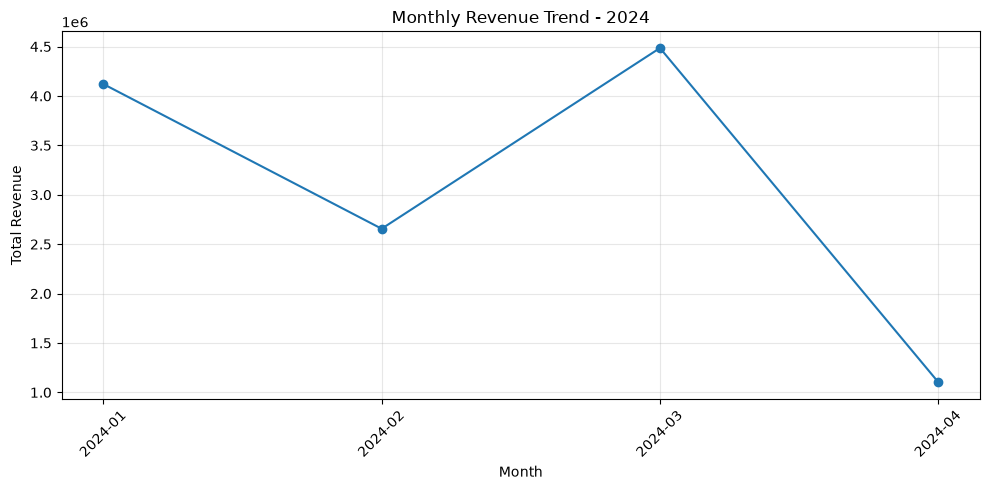

In [32]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales["Month"].astype(str),
    monthly_sales["Total_Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend - 2024")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


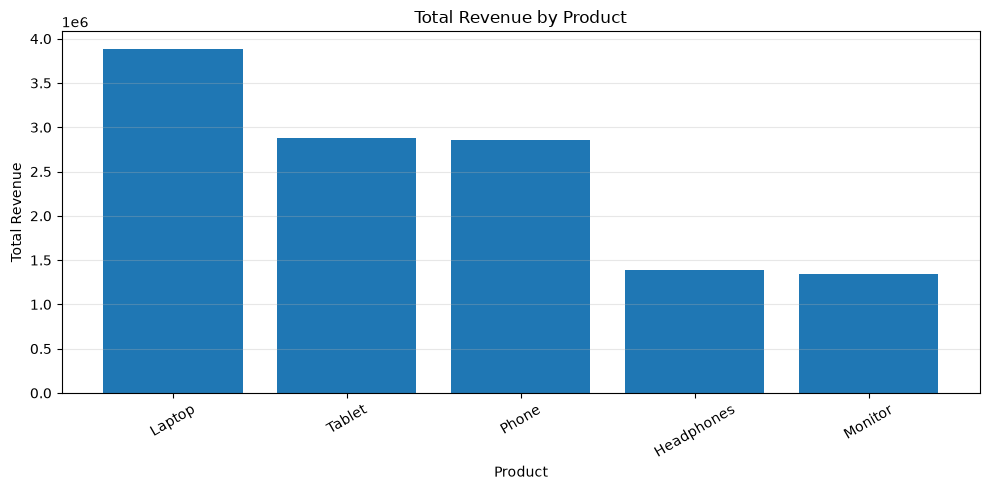

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    product_analysis["Product"],
    product_analysis["Total_Revenue"]
)

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()


In [34]:

import pandas as pd

revenue_pivot = pd.pivot_table(
    sales_df,
    values="Total_Sales",
    index="Product",
    columns="Region",
    aggfunc="sum",
    fill_value=0
)

print("Product Revenue by Region:")
print(revenue_pivot.to_string())


Product Revenue by Region:
Region        East    North    South    West
Product                                     
Headphones  288361   107091   512168  476413
Laptop      221946  1798206  1373120  495938
Monitor     642870   397100    39924  268177
Phone       506828   489284  1471428  391854
Tablet      859634  1191954   341212  491540


In [35]:

print("Churn value counts:")
print(customer_df["Churn"].value_counts().sort_index())

total_customers = len(customer_df)
churned_customers = (customer_df["Churn"] == 1).sum()

churn_rate = (churned_customers / total_customers) * 100

print("\nCustomer Churn Summary")
print("-" * 30)
print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churned_customers}")
print(f"Churn Rate: {churn_rate:.2f}%")


Churn value counts:
Churn
0    447
1     53
Name: count, dtype: int64

Customer Churn Summary
------------------------------
Total Customers: 500
Churned Customers: 53
Churn Rate: 10.60%


In [36]:

churn_by_contract = (
    customer_df.groupby("Contract")
    .agg(
        Total_Customers=("Churn", "count"),
        Churned_Customers=("Churn", "sum"),
        Churn_Rate=("Churn", "mean")
    )
    .reset_index()
)

churn_by_contract["Churn_Rate"] *= 100

churn_by_contract = churn_by_contract.sort_values(
    by="Churn_Rate",
    ascending=False
)

print("Churn Analysis by Contract:")
print(churn_by_contract.round(2).to_string(index=False))


Churn Analysis by Contract:
      Contract  Total_Customers  Churned_Customers  Churn_Rate
Month-to-month              170                 35       20.59
      Two year              144                 10        6.94
      One year              186                  8        4.30


In [37]:

churn_by_payment = (
    customer_df.groupby("PaymentMethod")
    .agg(
        Total_Customers=("Churn", "count"),
        Churned_Customers=("Churn", "sum"),
        Churn_Rate=("Churn", "mean")
    )
    .reset_index()
)

churn_by_payment["Churn_Rate"] *= 100

churn_by_payment = churn_by_payment.sort_values(
    by="Churn_Rate",
    ascending=False
)

print("Churn Analysis by Payment Method:")
print(churn_by_payment.round(2).to_string(index=False))


Churn Analysis by Payment Method:
   PaymentMethod  Total_Customers  Churned_Customers  Churn_Rate
     Credit Card              178                 24       13.48
Electronic Check              163                 18       11.04
   Bank Transfer              159                 11        6.92


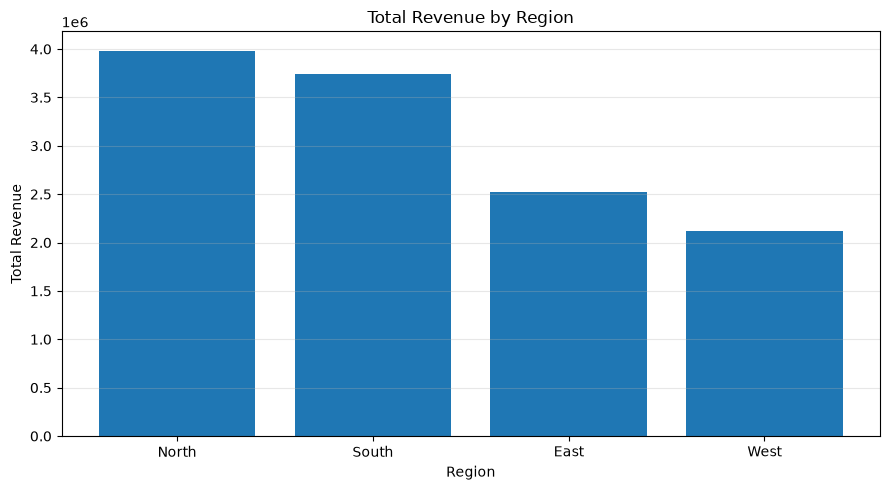

In [38]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    regional_analysis["Region"],
    regional_analysis["Total_Revenue"]
)

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/revenue_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


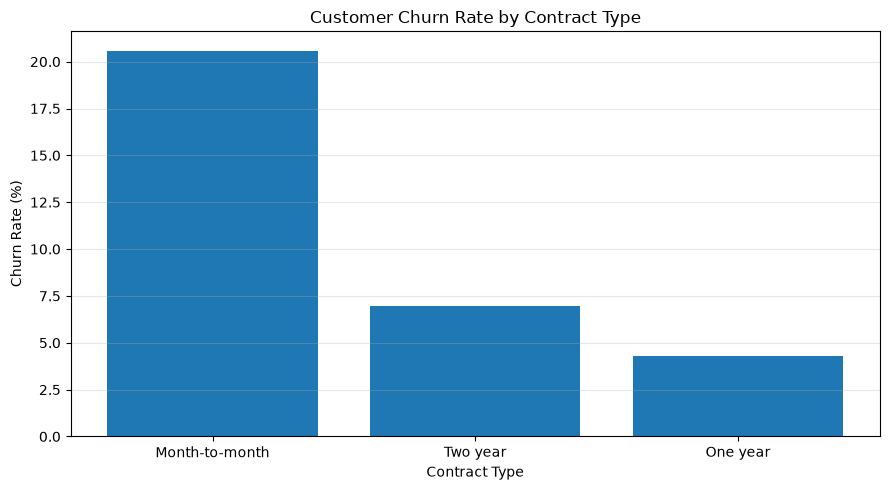

In [39]:

plt.figure(figsize=(9, 5))

plt.bar(
    churn_by_contract["Contract"],
    churn_by_contract["Churn_Rate"]
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


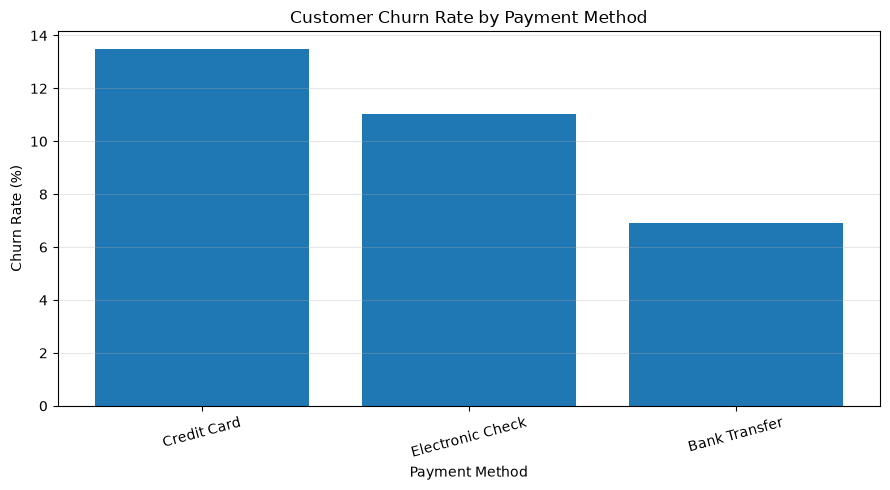

In [40]:

plt.figure(figsize=(9, 5))

plt.bar(
    churn_by_payment["PaymentMethod"],
    churn_by_payment["Churn_Rate"]
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/churn_by_payment_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


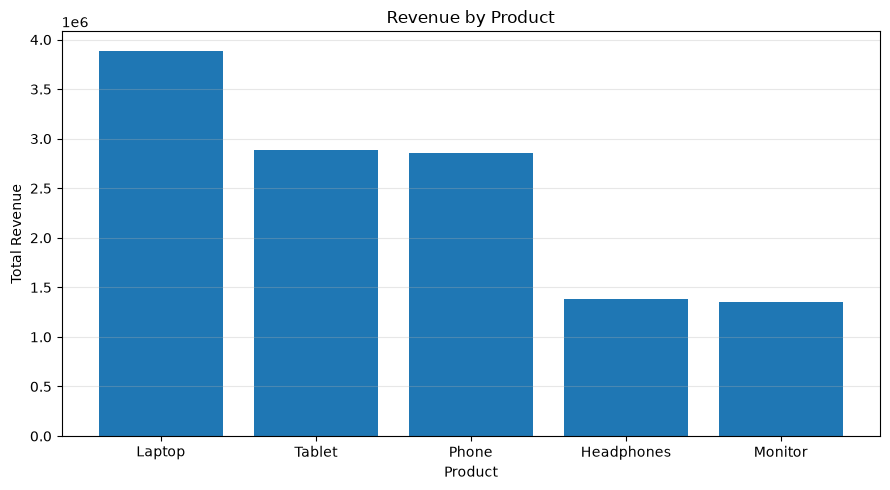

In [41]:

plt.figure(figsize=(9, 5))

plt.bar(
    product_analysis["Product"],
    product_analysis["Total_Revenue"]
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/revenue_by_product_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


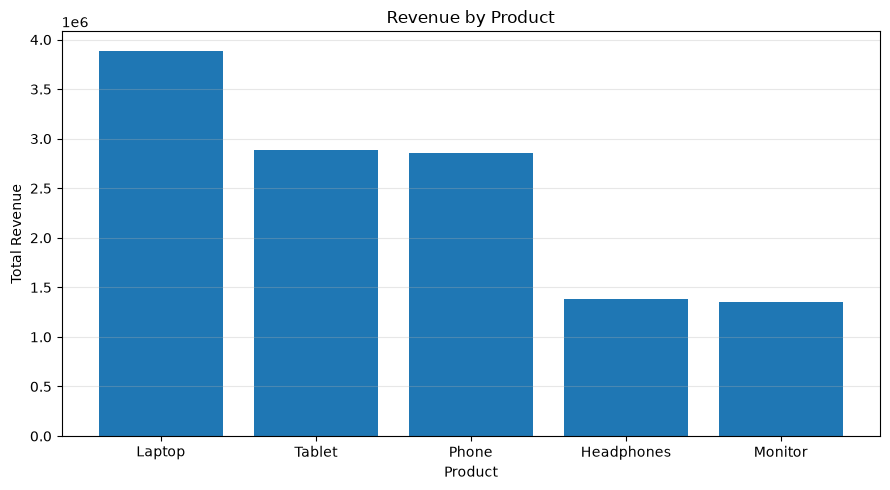

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    product_analysis["Product"],
    product_analysis["Total_Revenue"]
)

plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Total Revenue")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "visualizations/revenue_by_product_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
